# Introduction

Pour produire 1kg d'acier, il faut utilioser entre 300 et 600 litres d'eau. L'eau est largement utilisée dans l'industrie pour refroidir les centrales, laver et alimenter les machines... Les usines consomment donc beaucoup d'eau dans leur processus de production.  
Or, les usines ont tendance à s'agglomérer autour de grands sites industriels pour des raisons d'efficacité.  
Nous pouvons donc nous demander quel est l'état des nappes phréatiques autour de ces grands sites industriels.  


Problématique : L'implantation des nouvelles méga-usines (batteries, hydrogène, data centers) se fait-elle de manière aveugle dans des bassins versants déjà condamnés à un épuisement de leurs nappes phréatiques ?

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import requests as rq
import numpy as np
import time
import os
import contextily as ctx

# Récupération des données

### Récupération des données sur les installations industrielles
On utilise l'API de Georisques pour récupérer les informations sur les usines.

In [2]:
#On crée le dossier data qui va stocker toutes nos données :
os.makedirs("../../data", exist_ok=True)

#On récupère la liste des installations industrielles à l'échelle nationale sur le site de l'ICPE
url_icpe = "https://mapsref.brgm.fr/wxs/georisques/georisques_dl?&service=wfs&version=2.0.0&request=getfeature&typename=InstallationsClassees&outputformat=CSVTEXT"
lien_stockage_physique_icpe = "../../data/icpe.csv"

if not os.path.exists(lien_stockage_physique_icpe):
    fichier_icpe = rq.get(url_icpe)

    if fichier_icpe.status_code == 200:
        with open(lien_stockage_physique_icpe, "wb") as f:
            f.write(fichier_icpe.content)
        print("Fichier téléchargé.")
    else:
        print("Erreur avec le téléchargement du fichier ICPE.")
else:
    print("Le fichier a déjà été téléchargé.")

Le fichier a déjà été téléchargé.


On a  136450 installations industrielles. Dont  104757 installations industrielles ICPE.
On ne garde que les  43716 installations industrielles pures.


Text(0, 0.5, "Nombre d'installations industrielles")

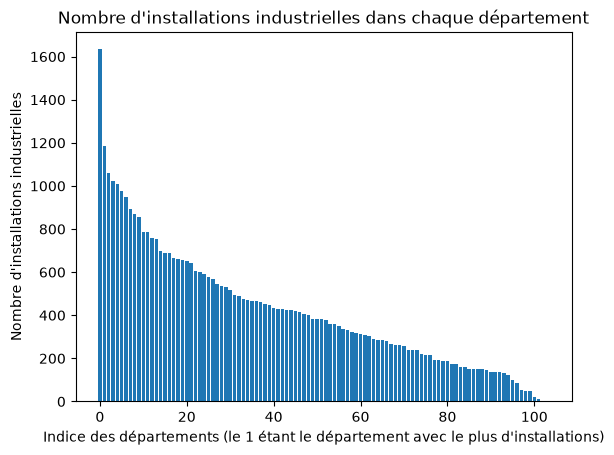

In [3]:
# On récupère donc la liste des installations industrielles
installations_indust = pd.read_csv(lien_stockage_physique_icpe, sep=";", encoding='utf-8')
print("On a ", installations_indust.shape[0], "installations industrielles.", end="")
installations_indust = installations_indust.loc[installations_indust["lib_regime"] != "Non ICPE"]
print(" Dont ", installations_indust.shape[0], "installations industrielles ICPE.")

#On veut garder uniquement les installations industrielles pures (pas l'agriculture et l'élevage par ex)
installations_indust = (installations_indust.loc[
    (installations_indust["industrie"] == 1)
    & (installations_indust["bovins"] == 0)
    & (installations_indust["porcs"] == 0)
    & (installations_indust["volailles"] == 0)
    & (installations_indust["eolienne"] == 0)
    ])
print("On ne garde que les ", installations_indust.shape[0], "installations industrielles pures.")

#On classe les départements qui ont le plus d'installations industrielles pour limiter la recherche (car les données sur Hub'eau sont trop volumineuses pour traiter la France entière)
classement_dpt = (installations_indust.groupby("num_dep")
    .size()
    .sort_values(ascending=False)
    )
plt.bar(range(classement_dpt.shape[0]), classement_dpt.values)
plt.title("Nombre d'installations industrielles dans chaque département")
plt.xlabel("Indice des départements (le 1 étant le département avec le plus d'installations)")
plt.ylabel("Nombre d'installations industrielles")

On va donc prendre le département qui contient le plus d'installations industrielles pour notre analyse.  
En effet, Hub'eau API nous donne un très grand volume de données et nous devons nous limiter dans notre recherche à quelques départements.  
Avec le graphique ci-dessus, on voit que le département 59 est de loin le plus grand centre industriel français.  
Nous nous concentrerons donc sur le département 59 pour la suite de l'analyse.  

In [4]:
departement_cible = classement_dpt.index[0]
print("Département analysé : ", departement_cible)

Département analysé :  59


Mise en forme des données géographiques avec Geopandas

In [5]:
installations_indust = installations_indust.loc[installations_indust["num_dep"] == departement_cible]

#On vérifie qu'il n'y a pas d'installations industrielles sans coordonnées géographiques dans la base de données ICPE des installations industrielles du 59
nb_position_less = installations_indust.loc[installations_indust["x"].isnull() | installations_indust["y"].isnull() | installations_indust["code_epsg"].isnull()].shape[0]
print(nb_position_less, "installations industrielles n'ont pas de coordonnées géographiques.")
installations_indust = installations_indust.loc[installations_indust["x"].notnull() & installations_indust["y"].notnull() & installations_indust["code_epsg"].notnull()]

#On utilise les coordonnées des installations pour les localiser avec Geopandas
installations_indust["geometry"] = None #Colonne qui va prendre la valeur position Geopandas
codes_epsg_type_coord = installations_indust["code_epsg"].unique()   #On veut que ça marche pour les différents types de référentiels (x,y)
for epsg in codes_epsg_type_coord:
    filtre = installations_indust["code_epsg"] == epsg
    points = gpd.points_from_xy(
        installations_indust.loc[filtre, "x"], 
        installations_indust.loc[filtre, "y"]
    )
    serie_geometrique = gpd.GeoSeries(points, crs=f"EPSG:{int(epsg)}")
    serie_geometrique = serie_geometrique.to_crs("EPSG:2154") #On ramène tout sous le même format
    installations_indust.loc[filtre, "geometry"] = serie_geometrique.values

#On définit un GeoDataFrame pour les études géométriques :
installations_indust = gpd.GeoDataFrame(installations_indust, geometry="geometry", crs="EPSG:2154")

0 installations industrielles n'ont pas de coordonnées géographiques.


### Récupération des données sur les nappes phréatiques du 59

L'API Hub'eau ne permet pas d'envoyer toutes les stations d'un coup.  
Encore moins toutes les chroniques d'un coup.  
Donc on sélectionne que la région pour laquelle on a vu qu'il y avait une grande concentration d'industrie : le 59

In [9]:
#On récupère les stations de mesure des nappes phréatiques sur le site Hubeau
url_stations = "https://hubeau.eaufrance.fr/api/v1/niveaux_nappes/stations"
chemin_fichier_stations = "../../data/stations_nappes.csv"

stations = []

params = {"code_departement": departement_cible, "size": 5000, "format": "json"}

if not os.path.exists(chemin_fichier_stations):
    fichier_stations = rq.get(url_stations, params=params)

    if fichier_stations.status_code == 200:
        data = fichier_stations.json()
        stations.extend(data["data"])
        print("Fichier téléchargé.")
    else:
        print(fichier_stations.status_code)
        print("Erreur avec le téléchargement du fichier stations Hubeau.")

    stations = pd.DataFrame(stations)
    stations.to_csv(chemin_fichier_stations, encoding='utf-8')
    print("On a récupéré ", stations.shape[0], "stations de mesure des nappes phréatiques dans le département ", departement_cible, ".")
else:
    stations = pd.read_csv(chemin_fichier_stations, encoding='utf-8')
    print("Le fichier a déjà été téléchargé.")

Fichier téléchargé.
On a récupéré  730 stations de mesure des nappes phréatiques dans le département  59 .


Mise en forme des données géographiques avec Geopandas

In [10]:
#On vérifie qu'il n'y a pas d'installations industrielles sans coordonnées géographiques dans la base de données ICPE des installations industrielles du 59
nb_position_less = stations.loc[stations["x"].isnull() | stations["y"].isnull()].shape[0]
print(nb_position_less, "stations n'ont pas de coordonnées géographiques.")
stations = stations.loc[stations["x"].notnull() & stations["y"].notnull()]

#On crée le modèle Geopandas
stations = gpd.GeoDataFrame(
    stations,
    geometry=gpd.points_from_xy(stations['x'], stations['y']),
    crs="EPSG:4326"
).to_crs(epsg=2154) #On ramène tout sous le même format que les installations industrielles

0 stations n'ont pas de coordonnées géographiques.


Pour chaque station identifiée dans les départements contenant le plus d'industrie, on récupère les séries temporelles de niveau des nappes phréatiques entre janvier 2015 et janvier 2026

In [11]:
chemin_fichier_chroniques = "../../data/chroniques_nappes.csv"

if not os.path.exists(chemin_fichier_chroniques):
    #On ne peut pas récupérer le volume des nappes phréatiques pour toutes les stations en même temps.


    #On veut récupérer les volumes des nappes phréatiques pour chaque station
    url_chroniques_api = "https://hubeau.eaufrance.fr/api/v1/niveaux_nappes/chroniques"
    chroniques = []

    #Quand on essaye de récupérer toutes les données de toutes les nappes, on a une erreur 414 : la requête URL est trop longue avec tous les code_bss en paramètres.
    #Donc on va diviser les données de 700 stations à récupérer en paquets de 50.

    liste_codes_bss_stations = stations["code_bss"].tolist()
    paquets_intermediaires = []
    for i in range(0, stations.shape[0], 50):
        paquets_intermediaires.append(liste_codes_bss_stations[i:i+50])
    print("Nombre de stations par paquets : ", [len(x) for x in paquets_intermediaires])

    for paquet in paquets_intermediaires:
        params_api = {"code_bss":",".join(paquet), "size":5000, "format":"json", "date_debut_mesure":"2015-01-01", "date_fin_mesure":"2026-01-01"}

        #Le problème est que le volume de données retourné est trop important. => On obtient une erreur 206 pour chaque paquet.
        #Il faut donc récupérer les premières informations renvoyées par l'API et aller chercher la page suivante.
        url = url_chroniques_api
        while url != None:
            try:
                fichier_chroniques = rq.get(url, params=params_api, timeout=20)    #On met un timeout pour rapidement recommencer la requête si ça marche pas.
            except Exception as e:
                print("Erreur requête : ", end="")
                print(e)
                print("Pas grave, on va réessayer.")
                continue
            #On recommence en haut de la boucle sur la même URL
            if fichier_chroniques.status_code == 200 or fichier_chroniques.status_code == 206:
                data = fichier_chroniques.json()
                chroniques.extend(data["data"])
                url = data.get("next")
                params_api = None   #Il semble que cette information soit déjà intégrée dans l'url de la page "next"
                print("Sous-paquet téléchargé.")
                time.sleep(1)   #On attend 1 sec pour éviter de se faire rejeter par le serveur
            else:
                print(fichier_chroniques.status_code)
                print("Erreur avec le téléchargement du fichier stations Hubeau.")
                time.sleep(1)   #On attend 1 seconde et on recommence au cas où ça se répare tout seul
    print("Téléchargement des donné réussi !")

    chroniques = pd.DataFrame(chroniques)
    chroniques.to_csv(chemin_fichier_chroniques, encoding='utf-8')

else:
    chroniques = pd.read_csv(chemin_fichier_chroniques, encoding='utf-8')
    print("Le fichier a déjà été téléchargé.")

Nombre de stations par paquets :  [50, 50, 50, 50, 50, 50, 50, 50, 50, 50, 50, 50, 50, 50, 30]


Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Erreur requête : HTTPSConnectionPool(host='hubeau.eaufrance.fr', port=443): Read timed out. (read timeout=20)
Pas grave, on va réessayer.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Erreur requête : HTTPSConnectionPool(host='hubeau.eaufrance.fr', port=443): Read timed out. (read timeout=20)
Pas grave, on va réessayer.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous

On nettoie les données des séries temporelles des nappes phréatiques

In [12]:
chroniques['date_mesure'] = pd.to_datetime(chroniques['date_mesure'])
print("Nombre de chroniques sans niveau d'eau : ", chroniques.loc[chroniques["niveau_nappe_eau"].isnull()].shape[0])
#On supprime les chroniques pour lesquelles le niveau d'eau est NULL
chroniques = chroniques.loc[chroniques["niveau_nappe_eau"].notnull()]

Nombre de chroniques sans niveau d'eau :  0


### Test des données

Un exemple de série temporelle pour une station (nappe phréatique)

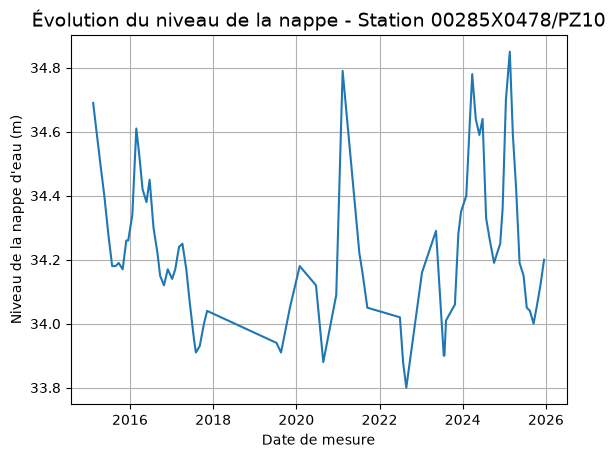

In [31]:
# Représentation d'une série temporelle d'une station
station_cible = '00285X0478/PZ10'
serie_station = chroniques.loc[chroniques['code_bss'] == station_cible]
serie_station = serie_station.sort_values(by='date_mesure')

plt.plot(serie_station['date_mesure'], serie_station['niveau_nappe_eau'])

plt.title(f"Évolution du niveau de la nappe - Station {station_cible}", fontsize=14)
plt.xlabel("Date de mesure")
plt.ylabel("Niveau de la nappe d'eau (m)")
plt.grid(True)

### Nettoyage et standardisation des données

Les séries temporelles de Hub'eau donnent des mesures des nappes phréatiques à des dates différentes entre les stations.  
Pour les calculs futurs, on va standardiser ça en faisant une moyenne par station et par mois

In [32]:
chroniques['date_mois_annee'] = chroniques['date_mesure'].dt.to_period('M')
chroniques

chroniques_niveau_mensuel = (chroniques.groupby(["code_bss", "date_mois_annee"])
              .agg({
                  "niveau_nappe_eau":"mean",
                  "profondeur_nappe":"mean"
              })
              .reset_index()
    )
chroniques_niveau_mensuel["date_mesure"] = chroniques_niveau_mensuel["date_mois_annee"].dt.to_timestamp()
chroniques_niveau_mensuel['date_mesure'] = pd.to_datetime(chroniques_niveau_mensuel['date_mesure'])
chroniques = chroniques_niveau_mensuel.copy()
print("Les données ont été normalisées en moyenne par mois pour chaque station.")

Les données ont été normalisées en moyenne par mois pour chaque station.


### Premier résultat : Répartition des usines et des stations hydrologiques dans le Nord

Text(0.5, 1.0, 'Répartition des usines ICPE et des stations hydrologiques dans le département')

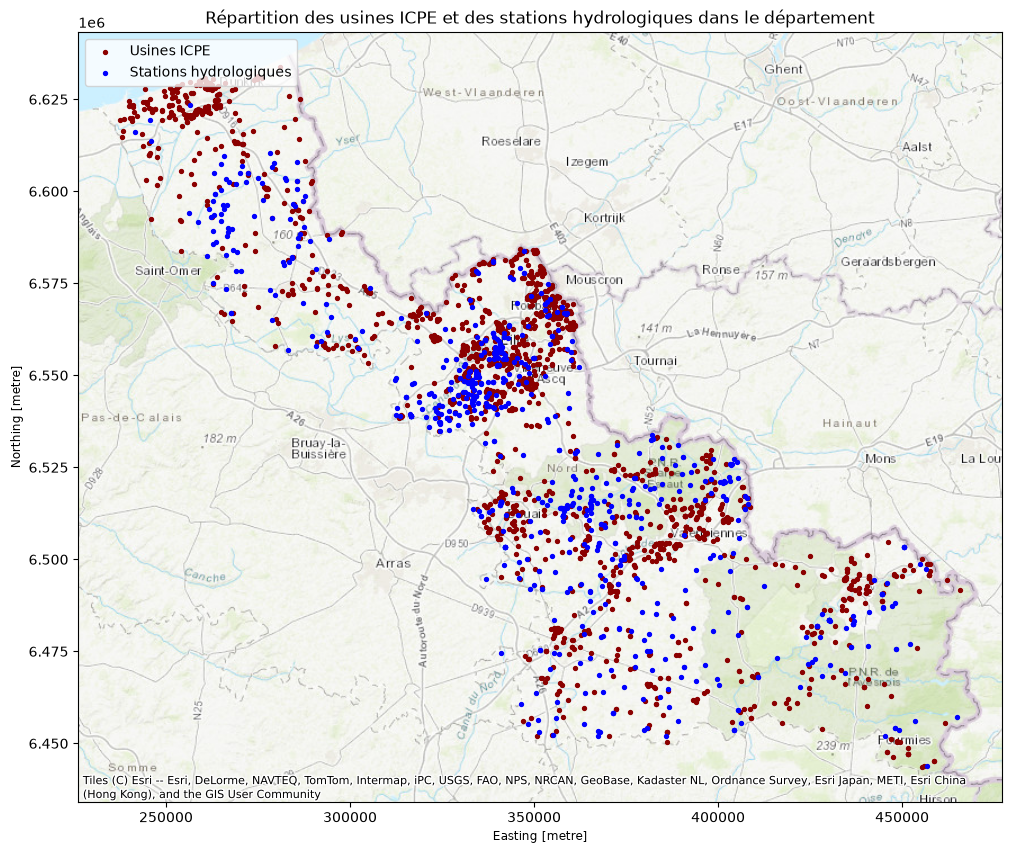

In [33]:
# Stations (points bleus, taille réduite, avec un fin contour blanc pour la lisibilité)
ax = plt.subplots(figsize=(12, 10))[1]
installations_indust.to_crs(epsg=3857).plot(ax=ax, color="darkred", markersize=8, label="Usines ICPE", zorder=1)
stations.to_crs(epsg=3857).plot(ax=ax, color="blue", markersize=8, label="Stations hydrologiques", zorder=2)
ctx.add_basemap(ax, source=ctx.providers.Esri.WorldTopoMap)
plt.legend(loc="upper left")
plt.title("Répartition des usines ICPE et des stations hydrologiques dans le département")

### On cherche la quantité d'usines par station

In [34]:
#On veut le nombre d'usines qui sont dans les 5km de chaque station
r = 5 * 1000

stations_rayon = stations.copy()
stations_rayon["geometry"] = stations_rayon.geometry.buffer(r)  #On suppose que la station prend toute la place dans un rayon de 5km autour du point où elle est réellement

usines_ds_rayon = gpd.sjoin(installations_indust, stations_rayon, how="inner", predicate="within")
nb_usine_ds_rayon = usines_ds_rayon.groupby("code_bss").size().reset_index(name="nb_usines_5km")

stations = stations.merge(nb_usine_ds_rayon, on="code_bss", how="left")
stations["nb_usines_5km"] = stations["nb_usines_5km"].fillna(0).astype(int) #On remplace les valeurs nulles par 0

#On rajoute une colonne dans le tableau chroniques qui indique la pression industrielle (nb d'usines dans un rayon de 5km qui exploitent probablement la nappe)
chroniques = chroniques.merge(stations[["code_bss", "nb_usines_5km"]], on="code_bss", how="inner")


Text(0.5, 0, 'Date')

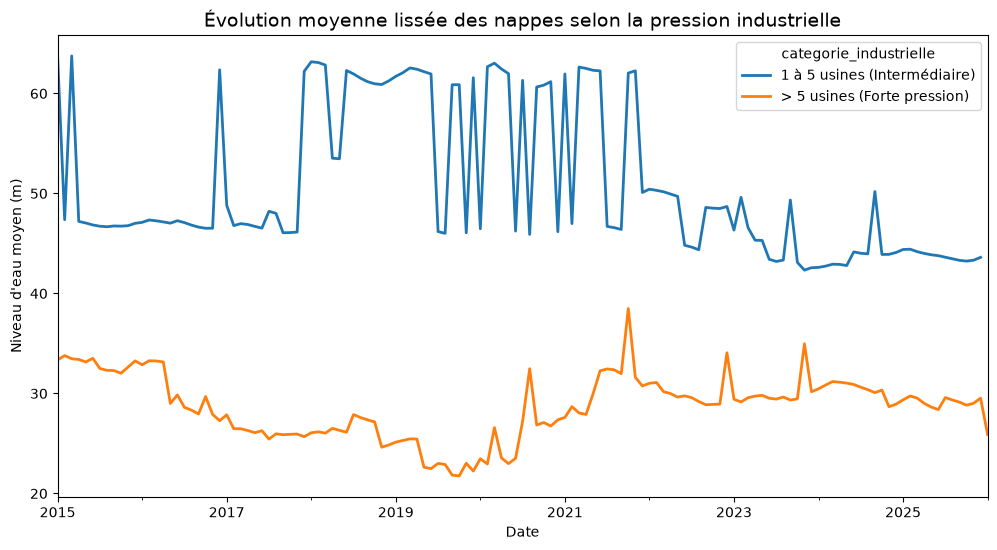

In [35]:
# Visualisation
conditions = [
    (chroniques['nb_usines_5km'] == 0),
    (chroniques['nb_usines_5km'] > 0) & (chroniques['nb_usines_5km'] <= 5),
    (chroniques['nb_usines_5km'] > 5)
]
choix = ['0 usine (Zone rurale)', '1 à 5 usines (Intermédiaire)', '> 5 usines (Forte pression)']
chroniques['categorie_industrielle'] = np.select(conditions, choix, default='Inconnu')

evolution_lisse = chroniques.groupby(['date_mois_annee', 'categorie_industrielle'])['niveau_nappe_eau'].mean().unstack()

evolution_lisse.plot(figsize=(12, 6), linewidth=2)
plt.title("Évolution moyenne lissée des nappes selon la pression industrielle", fontsize=14)
plt.ylabel("Niveau d'eau moyen (m)")
plt.xlabel("Date")

On observe que, en moyenne, les nappes qui ont plus de 5 usines à moins de 5km ont un niveau inférieur de 20m.  
Nous n'avons pourtant toujours pas établi de causalité. Les conditions géographiques et l'environnement peuvent également affecter ces nappes.

Les nappes phréatiques sont affectées majoritairement par 3 choses :  
- L'altitude, la topographie et la géologie  
- La pluie  
- L'industrie

## I. On va d'abord s'intéresser aux conditions géographiques de la nappe

## 1. Prise en compte de l'effet de l'altitude de la nappe

1. Commençons par un état des lieux de l'altitude des différentes stations.

Text(0.5, 1.0, 'Altitude des stations hydrologiques')

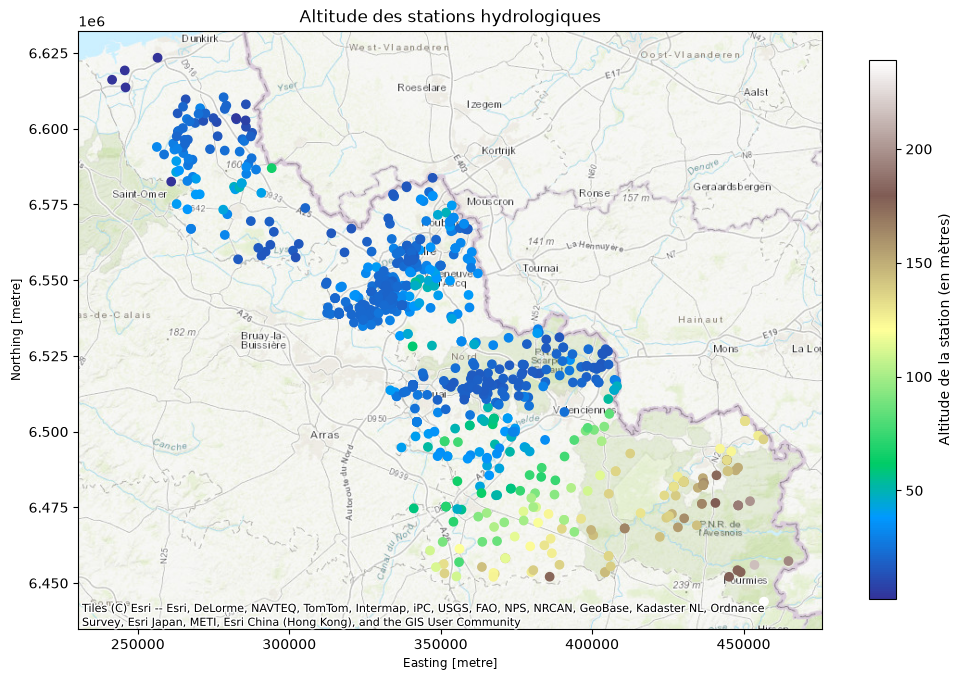

In [36]:
stations['altitude_station'] = pd.to_numeric(stations['altitude_station'])
points_carte = stations.to_crs(epsg=3857)   #on transforme le geopandas avec le code EPSG utilisé par les cartes et Google

fig, ax = plt.subplots(figsize=(12, 10))
points_carte.plot(ax=ax,
    column='altitude_station', # variable qui donne la couleur du point
    cmap='terrain', # fond de carte pour la topographie
    legend=True,                 # Affichage de la barre de gradient
    legend_kwds={
        'label': "Altitude de la station (en mètres)",
        'shrink': 0.7   #Limite la taille de la barre de la légende
    },
    zorder=2
)
ctx.add_basemap(ax, source=ctx.providers.Esri.WorldTopoMap, zorder=1)   #Fonds de carte
plt.title("Altitude des stations hydrologiques")

2. Annulation de l'effet de l'l'altitude sur le niveau des nappes.

La variable niveau_nappe_eau nous donne le niveau de l'eau de la nappe par rapport au niveau de la mer. Pas par rapport au fond de la nappe. On ne peut pas obtenir le volume d'eau dans la nappe. On ne peut qu'observer le niveau de l'eau dans la nappe.  
Nous allons donc étudier les variations du niveau de la nappe sur la moyenne historique afin de déterminer si l'industrie creuse les nappes.  
On va annuler l'effet de l'altitude sur le niveau de l'eau dans la station pour pouvoir comparer les niveau d'eau dans les différentes stations.  
Pour cela, on va centrer le niveau pour ne garder que les variations de niveau des nappes :  
Exemple : si on a en moyenne une hauteur de 100m pour une station, après une sécheresse qui fait baisser ce niveau à 90m, on aura -10 de variation sur notre chronique.

In [37]:
moyenne_par_station = chroniques.groupby("code_bss")["niveau_nappe_eau"].mean().reset_index()
moyenne_par_station = moyenne_par_station.rename(columns={"niveau_nappe_eau": "moyenne_de_station"})
chroniques = chroniques.merge(moyenne_par_station, on="code_bss", how="left")   #On rajoute la colonne dans le DataFrame de base en affectant à chaque ligne d'observation une colonne avec la moyenne de sa station

chroniques["niveau_eau_isole"] = chroniques["niveau_nappe_eau"] - chroniques["moyenne_de_station"]

print(chroniques[["code_bss", "date_mesure", "niveau_nappe_eau", "niveau_eau_isole"]].sample(15))

             code_bss date_mesure  niveau_nappe_eau  niveau_eau_isole
3238    00281X0002/F1  2024-05-01         12.484516          2.905610
4975     BSS004CFVG/X  2023-05-01          7.041613         -0.390908
1743  00202A0460/PZ12  2020-01-01         11.154194         -3.523796
5681     BSS004LJLE/X  2016-06-01         16.950000          0.716753
881    00146X2040/PZ5  2022-08-01         16.144839         -0.295786
3041   00278X0132/PZ7  2023-11-01         33.300000          0.170200
829   00146B0737/PZR2  2022-04-01         11.857000         -0.628091
3831    00291X0031/P1  2022-12-01         29.284194         -1.515635
3088   00278X0133/PZ8  2021-08-01         33.620000         -0.093590
3313    00281X0004/F1  2019-08-01         27.485484         -1.730275
5973     BSS004LJLJ/X  2020-05-01         14.560000         -0.279867
4155    00377X0051/S1  2017-01-01         92.321613          0.391399
5263     BSS004GZEL/X  2025-01-01         17.270000          1.130989
5868     BSS004LJLF/

## 2. Prise en compte de l'effet de la nature des sols

On va vérifier si l'effet de la géologie doit être pris en compte.  
En effet, on peut supposer que selon la nature du sol, les nappes phréatiques peuvent se vider plus ou moins rapidement et les variations de niveau peuvent donc être impactés.  
Il y a de nombreux types de sols. On va donc se concentrer sur les 5 les plus courants pour vérifier notre hypothèse  

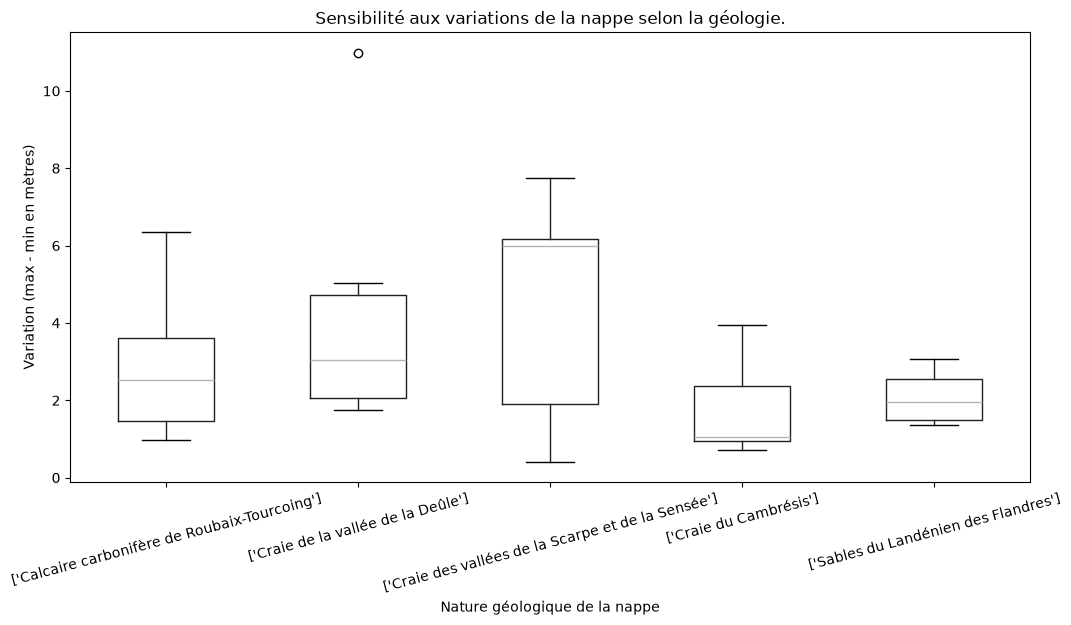

In [38]:
#Nettoyage de type :
stations['noms_masse_eau_edl'] = stations['noms_masse_eau_edl'].astype(str)

#Calcul des variations du niveau de chaque nappe
amplitude = chroniques.groupby('code_bss')['niveau_nappe_eau'].agg(lambda x: x.max() - x.min()).reset_index()
amplitude = amplitude.rename(columns={'niveau_nappe_eau': 'amplitude_metres'})
stations = stations.merge(amplitude, on='code_bss', how='inner')

#On prend les 5 sols les plus fréquents
compte = stations.groupby('noms_masse_eau_edl').size()
tri = compte.sort_values(ascending=False)
top_5_sols = tri.head(5).index

stations_top = stations[stations['noms_masse_eau_edl'].isin(top_5_sols)]
stations_top.boxplot(column='amplitude_metres', by='noms_masse_eau_edl', grid=False, rot=15, figsize=(12, 6))
plt.title("Sensibilité aux variations de la nappe selon la géologie.")
plt.suptitle("") # sinon pPandas met un sous-titre automatique
plt.ylabel("Variation (max - min en mètres)")
plt.xlabel("Nature géologique de la nappe")
plt.show()

On va créer une colonne qui met des labels sur les types géologiques. On pourra ainsi prendre en compte cet effet dans la suite de notre étude.

In [39]:
#Petit nettoyage de type
stations['noms_masse_eau_edl'] = stations['noms_masse_eau_edl'].astype(str)

#Familles de sols
conditions_geo = [
    stations['noms_masse_eau_edl'].str.contains('Craie', case=False, na=False),
    stations['noms_masse_eau_edl'].str.contains('Sable|Landénien', case=False, na=False),
    stations['noms_masse_eau_edl'].str.contains('Calcaire', case=False, na=False)
]
labels_type_station = ['Craie (Forte amplitude)', 'Sable (Faible amplitude)', 'Calcaire (Amplitude modérée)']

#On ajoute la colonne au dataframe
stations['famille_geologique'] = np.select(conditions_geo, labels_type_station, default='Autre')
print(stations['famille_geologique'].value_counts())

famille_geologique
Craie (Forte amplitude)         31
Autre                           17
Calcaire (Amplitude modérée)    11
Sable (Faible amplitude)         8
Name: count, dtype: int64


Après vérification, dans la catégorie autre, on ne retrouve quasiment que des types de sols NaN.

## 3. Prise en compte de l'effet de la topologie (distance entre la surface et la nappe)

On va vérifier si l'effet de la topologie a un effet (à annuler pour notre analyse) sur le niveau des nappes phréatiques

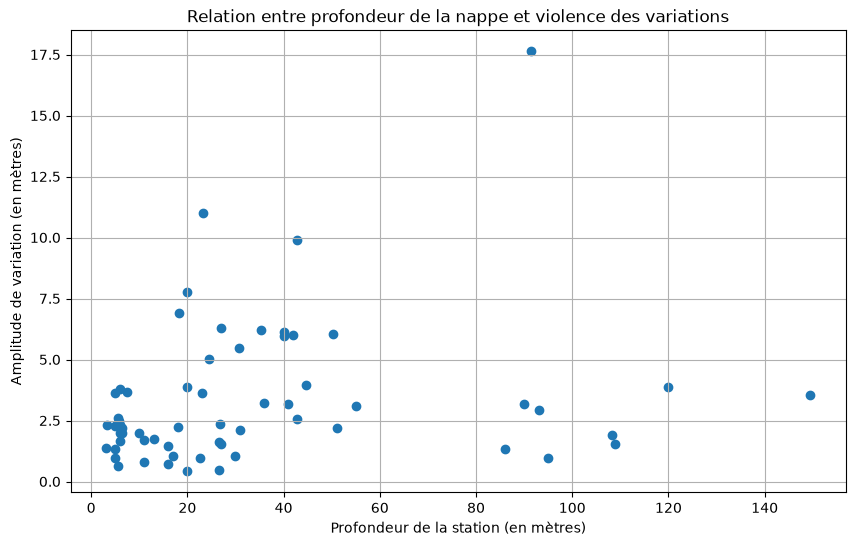

In [40]:
plt.figure(figsize=(10, 6))
# On limite l'axe X à 150m pour ne pas écraser le graphique avec les extrêmes
donnees_visuelles = stations[stations['profondeur_investigation'] < 150]

plt.scatter(donnees_visuelles['profondeur_investigation'], donnees_visuelles['amplitude_metres'])
plt.title("Relation entre profondeur de la nappe et violence des variations")
plt.xlabel("Profondeur de la station (en mètres)")
plt.ylabel("Amplitude de variation (en mètres)")
plt.grid(True)
plt.show()

In [41]:
#Nouvelle colonne qui donne un label topologie à la station
stations['classe_profondeur'] = 'Non renseignée'

stations.loc[stations['profondeur_investigation'] < 30, 'classe_profondeur'] = 'Superficielle (<30m)'
stations.loc[(stations['profondeur_investigation'] >= 30) & (stations['profondeur_investigation'] <= 80), 'classe_profondeur'] = 'Intermédiaire (30-80m)'
stations.loc[stations['profondeur_investigation'] > 80, 'classe_profondeur'] = 'Profonde (>80m)'

print(stations['classe_profondeur'].value_counts())

classe_profondeur
Superficielle (<30m)      40
Intermédiaire (30-80m)    15
Profonde (>80m)           12
Name: count, dtype: int64


On voit qu'on a 40 stations superficielles qui devraient être les plus affectées par les installations industrielles.  
Le groupe des stations profondes qui ne devraient pas être très affectées par l'activité industrielle servira de groupe témoin.

## Recentrage sur les stations intéressantes
On remarque qu'on n'a plus que environ 70 stations alors qu'on en avait 730 au début.  
Cela est dû au inner join fait pour catégoriser les stations selon la géologie (avec le calcul de l'amplitude pour chaque type de sol).  
Vérifions à quoi ressemble les stations éliminées et leurs chroniques pour comprendre.

In [42]:
#On reprend la liste de toutes les stations
stations_brutes = pd.read_csv("../../data/stations_nappes.csv") 

codes_valides = chroniques['code_bss'].unique() #Stations qui ont été conservées dans le processus.
print("Stations conservées dans l'analyse : ", len(codes_valides))
print(stations[['code_bss', 'nom_commune', 'nb_mesures_piezo']].sort_values(by="nb_mesures_piezo", ascending=False).head(10))
stations_eliminees = stations_brutes[~stations_brutes['code_bss'].isin(codes_valides)]

#On regarde le nombre de mesures pour les stations éliminées :
print("Stations éliminées : ", len(stations_eliminees))
print(stations_eliminees[['code_bss', 'nom_commune', 'nb_mesures_piezo']].sort_values(by="nb_mesures_piezo", ascending=False).head(10))

Stations conservées dans l'analyse :  67
            code_bss            nom_commune  nb_mesures_piezo
30    00216X0073/PZ3               Lecelles             17017
7      00146B0007/F1                  Lille             15483
10     00143C0079/F1                Bondues             15183
14     00147D0218/P1                  Lille             13224
25     00148D0177/F2               Baisieux              9802
13     00291X0031/P1  Rombies-et-Marchipont              9210
24    00225X0077/FC2     Fresnes-sur-Escaut              9003
16     00217X0068/P1    Flines-lès-Mortagne              8614
6      00281X0004/F1                 Abscon              8609
1   00387X0184/PZCC1             Grand-Fayt              8596
Stations éliminées :  663
          code_bss          nom_commune  nb_mesures_piezo
260  00215X0140/P1           Bouvignies              9084
273  00225X0061/P1              Crespin              8236
78   00143B0102/F1            Tourcoing              6850
146  00281X0065/F1 

Donc on a un problème manifestement.  
Il est possible que les stations éliminées sont des stations qui n'ont pas enregistré de données entre 2015 et 2026 (car le nb_mesures_piezo est le nombre de mesures totales depuis la création de la station).

In [43]:
stations_eliminees['date_fin_mesure'] = pd.to_datetime(stations_eliminees['date_fin_mesure'])
#on regarde l'année d'arrêt de la station
stations_eliminees['annee_arret'] = stations_eliminees['date_fin_mesure'].dt.year

# On affiche l'année de fin d'activité pour les 10 plus grosses stations éliminées
colonnes_visibles = ['code_bss', 'nom_commune', 'nb_mesures_piezo', 'annee_arret']
print(stations_eliminees.sort_values(by="nb_mesures_piezo", ascending=False)[colonnes_visibles].head(10))

arret_avant_2015 = len(stations_eliminees[stations_eliminees['annee_arret'] < 2015])
jamais_mesure = len(stations_eliminees[stations_eliminees['annee_arret'].isna()])
print("Stations arrêtées définitivement avant 2015 : ", arret_avant_2015)
print("Stations sans date de fin : ", jamais_mesure)

print(stations_eliminees.loc[stations_eliminees['annee_arret'].isna()].sort_values(by="nb_mesures_piezo", ascending=False)[colonnes_visibles].head(10))

          code_bss          nom_commune  nb_mesures_piezo  annee_arret
260  00215X0140/P1           Bouvignies              9084       2004.0
273  00225X0061/P1              Crespin              8236       1996.0
78   00143B0102/F1            Tourcoing              6850       1996.0
146  00281X0065/F1              Rieulay              6676       2001.0
258  00385X0010/P1  Catillon-sur-Sambre              6617       2001.0
165  00201C0126/F1               Provin              6581       2004.0
131  00144C0005/F1            Wattrelos              6465       1987.0
413  00274X0014/F2              Anhiers              4762       2006.0
57   00273X0151/F1                Douai              4480       1997.0
307  00035X0045/P1           Loon-Plage              4260       1983.0
Stations arrêtées définitivement avant 2015 :  633
Stations sans date de fin :  30
           code_bss        nom_commune  nb_mesures_piezo  annee_arret
107   00207X0153/F1     Roost-Warendin                 0          

Donc c'est tout bon : seules les 67 stations gardées sont encore actives après 2015 et rentrent dans le cadre de notre étude.

## Conclusion partielle
On a annulé l'effet de l'altitude.  
On a segmenté les stations selon la géologie pour vérifier qu'elles ne biaisent pas les observations futures.  
On a segmenté les stations en un groupe expérience (stations superficielles affectées par l'industrie) et un groupe test (stations profondes).

# II. On va ensuite prendre en compte l'effet de la pluie

Avec le cycle naturel de l'eau, il est normal que l'eau joue un rôle important dans la variation du niveau des nappes phréatiques.  
Nous allons donc vérifier si cela peut impacter notre enquête.

In [44]:
url_1950_2024 = "https://www.data.gouv.fr/api/1/datasets/r/c2a9f75c-0554-48d6-ba1a-534b00063f89"
url_2025_2026 = "https://www.data.gouv.fr/api/1/datasets/r/e356abd8-90ff-4c7f-a0cd-55661c3be402"

chemin_1950_2024 = "../../data/meteo_59_1950_2024.csv.gz"
chemin_2025_2026 = "../../data/meteo_59_2025_2026.csv.gz"

os.makedirs("../../data", exist_ok=True)
fichiers_a_telecharger = [
    (url_1950_2024, chemin_1950_2024),
    (url_2025_2026, chemin_2025_2026)
]

for url, nom_fichier in fichiers_a_telecharger:
    if not os.path.exists(nom_fichier):
        reponse = rq.get(url)
        with open(nom_fichier, "wb") as fichier:
            fichier.write(reponse.content)
        print("Téléchargement terminé.")

meteo_1950_2024 = pd.read_csv(chemin_1950_2024, sep=";", compression="gzip")
meteo_2025_2026 = pd.read_csv(chemin_2025_2026, sep=";", compression="gzip")

# On enlève toutes les données avant 2015 pour ne garder que la période 2015-2026
meteo_2015_2024 = meteo_1950_2024[meteo_1950_2024["AAAAMMJJ"] >= 20150101]
meteo = pd.concat([meteo_2015_2024, meteo_2025_2026], ignore_index=True)

# Nettoyage : mise en forme de la date
meteo["date"] = pd.to_datetime(meteo["AAAAMMJJ"].astype(str), format="%Y%m%d")

print(meteo[["NUM_POSTE", "NOM_USUEL", "LAT", "LON", "ALTI", "date", "RR", "TM"]].head(5))

   NUM_POSTE    NOM_USUEL      LAT     LON  ALTI       date    RR  TM
0   59017001  ARMENTIERES  50.6935  2.8975    14 2015-01-01   0.3 NaN
1   59017001  ARMENTIERES  50.6935  2.8975    14 2015-01-02   1.0 NaN
2   59017001  ARMENTIERES  50.6935  2.8975    14 2015-01-03  11.0 NaN
3   59017001  ARMENTIERES  50.6935  2.8975    14 2015-01-04   0.6 NaN
4   59017001  ARMENTIERES  50.6935  2.8975    14 2015-01-05   0.0 NaN


Aux développeurs :  
Objectifs de cette partie : identifier les périodes de sécheresse, vérifier dans quelle mesure les variations des niveaux des nappes phréatiques s'explique par la pluie
Procédé : coupler les stations de météo aux stations de nappes, prendre en compte que la pluie arrive dans les nappes après au moins 2 semaines (selon la profondeur de la nappe (cf partie 1)

# III. Effet de l'industrie

### 1. Indicateur d'évolution des nappes

In [51]:
# Indicateur = différence entre niveau moyen en 2015-2017 et en 2023-2025
chroniques["annee"] = chroniques["date_mesure"].dt.year
annuel = chroniques.groupby(["code_bss", "annee"]).agg(niveau=("niveau_nappe_eau", "mean"), nb_mois=("niveau_nappe_eau", "size")).reset_index()
annuel = annuel[annuel["nb_mois"] >= 10]

debut = annuel[annuel["annee"].between(2015, 2017)].groupby("code_bss")["niveau"].agg(["mean", "size"])
fin = annuel[annuel["annee"].between(2023, 2025)].groupby("code_bss")["niveau"].agg(["mean", "size"])

evo = debut.join(fin, lsuffix="_debut", rsuffix="_fin", how="inner")
evo = evo[(evo["size_debut"] >= 2) & (evo["size_fin"] >= 2)]
evo["evolution_m"] = evo["mean_fin"] - evo["mean_debut"]
evo["evolution_relative"] = evo["evolution_m"] - evo["evolution_m"].median()

/tmp/ipykernel_76745/4265739253.py:9: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  evo = debut.join(fin, lsuffix="_debut", rsuffix="_fin", how="inner")


### 2. Indicateur de pression industrielle

In [52]:
code_naf = pd.to_numeric(installations_indust["code_naf"].astype(str).str[:2], errors="coerce")
usines = installations_indust[code_naf.between(10, 33) | (code_naf == 35)]
print("Usines retenues :", len(usines))

Usines retenues : 428


In [53]:
#On détermine le nombre d'usines autour de chaque station
#On teste plusieurs rayon pour voir la sensiblité des résultats face au choix du rayon
st = stations.merge(evo[["evolution_m", "evolution_relative"]].reset_index(), on="code_bss")
for r in [2, 5, 10]:
    st[f"usines_{r}km"] = st.geometry.apply(lambda g: (usines.distance(g) <= r * 1000).sum())

In [54]:
st["pression"] = pd.cut(st["usines_5km"], bins=[-1, 0, 5, 10000], labels=["0 usine", "1 à 5 usines", "plus de 5 usines"])

### 3. Visualistion de chaque variable

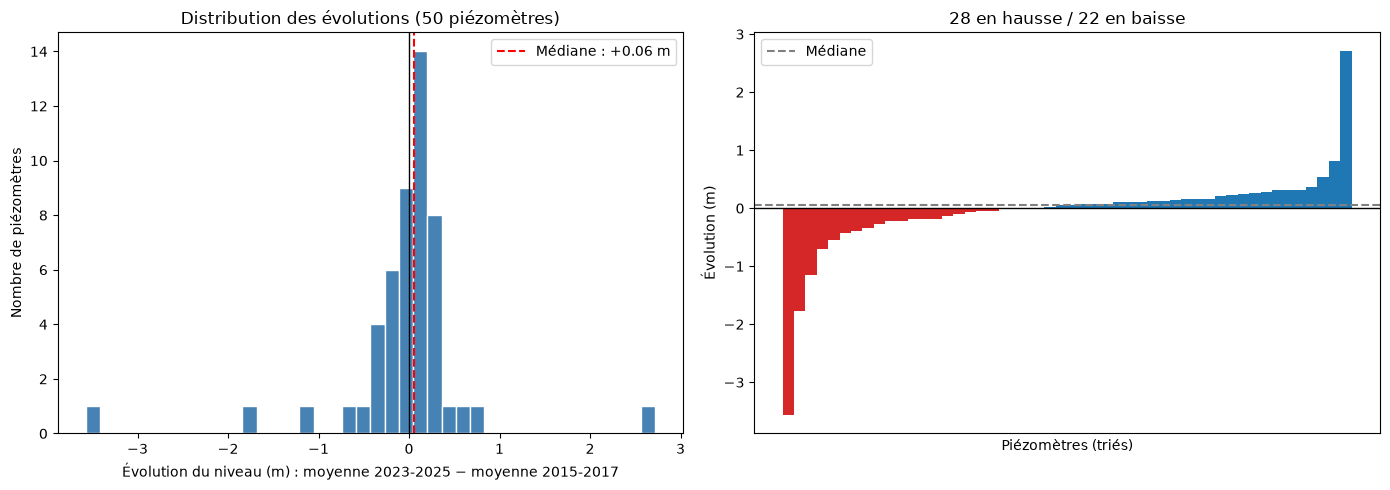

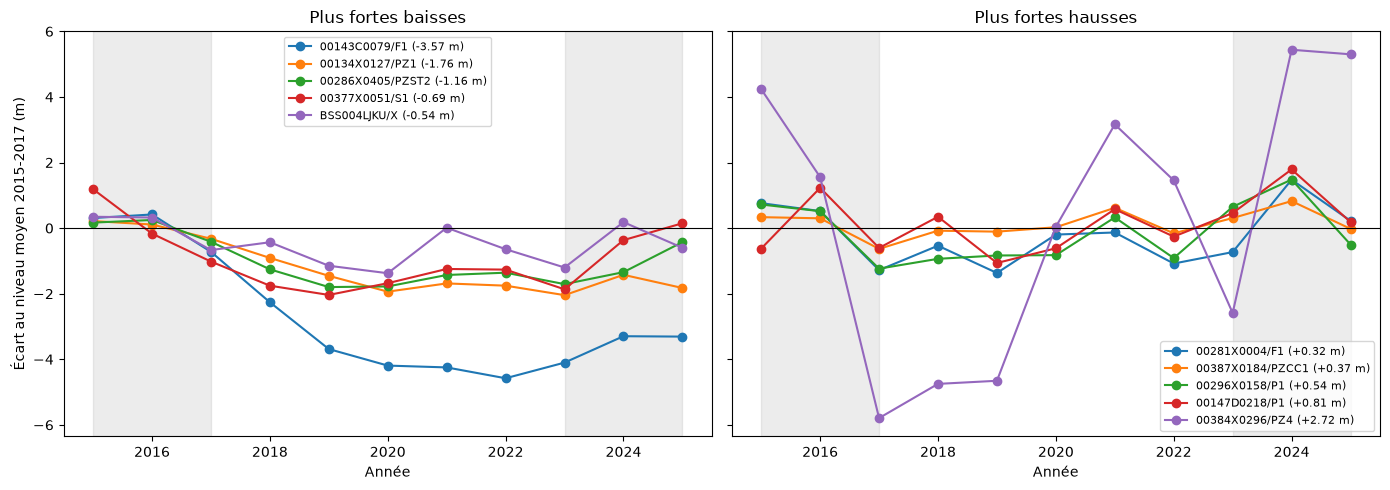

In [55]:
import matplotlib.pyplot as plt
import numpy as np

evo = evo.sort_values("evolution_m")
med = evo["evolution_m"].median()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Distribution des évolutions
ax = axes[0]
ax.hist(evo["evolution_m"], bins=40, color="steelblue", edgecolor="white")
ax.axvline(0, color="black", lw=1)
ax.axvline(med, color="red", ls="--", label=f"Médiane : {med:+.2f} m")
ax.set_xlabel("Évolution du niveau (m) : moyenne 2023-2025 − moyenne 2015-2017")
ax.set_ylabel("Nombre de piézomètres")
ax.set_title(f"Distribution des évolutions ({len(evo)} piézomètres)")
ax.legend()

# 2. Classement des piézomètres (une barre par station)
ax = axes[1]
couleurs = np.where(evo["evolution_m"] >= 0, "tab:blue", "tab:red")
ax.bar(range(len(evo)), evo["evolution_m"], color=couleurs, width=1.0)
ax.axhline(0, color="black", lw=1)
ax.axhline(med, color="gray", ls="--", label="Médiane")
ax.set_xticks([])
ax.set_xlabel("Piézomètres (triés)")
ax.set_ylabel("Évolution (m)")
n_hausse = (evo["evolution_m"] > 0).sum()
ax.set_title(f"{n_hausse} en hausse / {len(evo) - n_hausse} en baisse")
ax.legend()

plt.tight_layout()
plt.show()

# 3. Chroniques annuelles des 5 plus fortes baisses et 5 plus fortes hausses
extremes = list(evo.index[:5]) + list(evo.index[-5:])
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, codes, titre in [(axes[0], evo.index[:5], "Plus fortes baisses"),
                         (axes[1], evo.index[-5:], "Plus fortes hausses")]:
    for code in codes:
        serie = annuel[annuel["code_bss"] == code].sort_values("annee")
        # niveau centré sur la moyenne 2015-2017 pour comparer les stations entre elles
        ax.plot(serie["annee"], serie["niveau"] - evo.loc[code, "mean_debut"],
                marker="o", label=f"{code} ({evo.loc[code, 'evolution_m']:+.2f} m)")
    ax.axhline(0, color="black", lw=0.8)
    ax.axvspan(2015, 2017, color="gray", alpha=0.15)
    ax.axvspan(2023, 2025, color="gray", alpha=0.15)
    ax.set_title(titre)
    ax.set_xlabel("Année")
    ax.legend(fontsize=8)

axes[0].set_ylabel("Écart au niveau moyen 2015-2017 (m)")
plt.tight_layout()
plt.show()

On observe que la plupart des nappes sont stables, avec quelques cas extrêmes.

In [61]:
colonnes = ["code_bss", "nom_commune", "evolution_m", "usines_5km", "classe_profondeur", "famille_geologique"]
print(st.sort_values("evolution_m")[colonnes].head(8).to_string(index=False))
print(st.sort_values("evolution_m")[colonnes].tail(5).to_string(index=False))

        code_bss         nom_commune  evolution_m  usines_5km      classe_profondeur           famille_geologique
   00143C0079/F1             Bondues    -3.568473          21        Profonde (>80m) Calcaire (Amplitude modérée)
  00134X0127/PZ1              Nieppe    -1.764613          11 Intermédiaire (30-80m)     Sable (Faible amplitude)
00286X0405/PZST2 Villers-en-Cauchies    -1.159201           0   Superficielle (<30m)      Craie (Forte amplitude)
   00377X0051/S1            Neuvilly    -0.694987           3 Intermédiaire (30-80m)      Craie (Forte amplitude)
    BSS004LJKU/X     Beuvry-la-Forêt    -0.539708           5   Superficielle (<30m)                        Autre
 00215X0187/PZAE         Marchiennes    -0.424632           2   Superficielle (<30m)     Sable (Faible amplitude)
  00216X0073/PZ3            Lecelles    -0.385997          10 Intermédiaire (30-80m)      Craie (Forte amplitude)
   00124X0023/F1         Steenbecque    -0.340717           0        Profonde (>80m)    

In [56]:
print(pd.crosstab(st["classe_profondeur"], st["pression"], margins=True))

pression                0 usine  1 à 5 usines  plus de 5 usines  All
classe_profondeur                                                   
Intermédiaire (30-80m)        1             5                 6   12
Profonde (>80m)               1             3                 3    7
Superficielle (<30m)          4            16                11   31
All                           6            24                20   50


                  count  mean   std   min   25%   50%   75%   max
pression                                                         
0 usine             6.0 -0.14  0.61 -1.22 -0.32 -0.02  0.24  0.48
1 à 5 usines       24.0 -0.01  0.62 -0.76 -0.25 -0.05  0.04  2.66
plus de 5 usines   20.0 -0.21  0.94 -3.63 -0.15  0.08  0.18  0.75
pression                0 usine  1 à 5 usines  plus de 5 usines
classe_profondeur                                              
Intermédiaire (30-80m)     0.31          0.01             -0.16
Profonde (>80m)           -0.40          0.25             -0.10
Superficielle (<30m)      -0.02         -0.06              0.10


<Axes: title={'center': 'evolution_relative'}, xlabel='pression'>

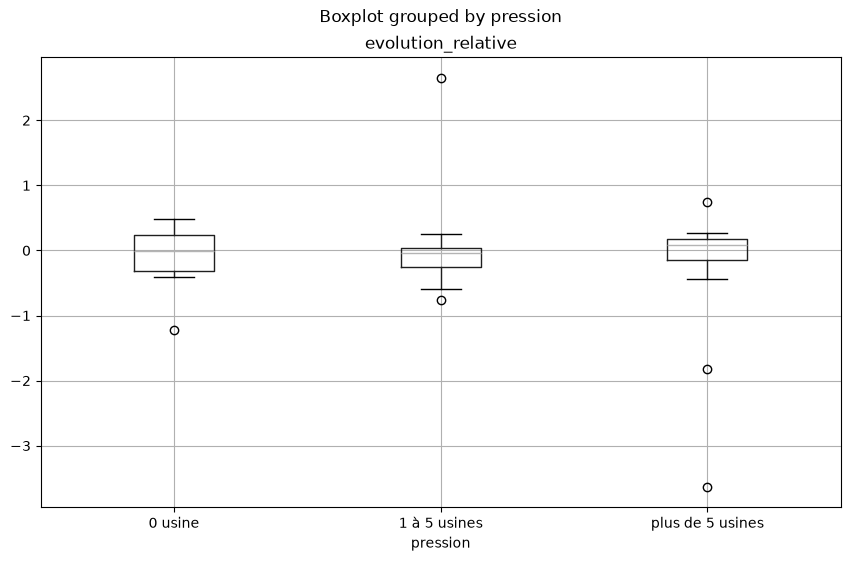

In [57]:
print(st.groupby("pression")["evolution_relative"].describe().round(2))
print(st.pivot_table(values="evolution_relative", index="classe_profondeur", columns="pression", aggfunc="median").round(2))
st.boxplot(column="evolution_relative", by="pression", figsize=(10, 6))

In [58]:
for r in [2, 5, 10]:
    print(r, "km :", round(st["evolution_relative"].corr(st[f"usines_{r}km"], method="spearman"), 2))

2 km : 0.25
5 km : 0.15
10 km : 0.17


In [59]:
print(st.groupby("famille_geologique")["evolution_relative"].describe().round(2))

                              count  mean   std   min   25%   50%   75%   max
famille_geologique                                                           
Autre                          14.0 -0.14  0.18 -0.60 -0.23 -0.11 -0.02  0.09
Calcaire (Amplitude modérée)    7.0 -0.10  1.85 -3.63 -0.22  0.17  0.28  2.66
Craie (Forte amplitude)        24.0 -0.00  0.39 -1.22 -0.06  0.06  0.19  0.75
Sable (Faible amplitude)        5.0 -0.53  0.76 -1.82 -0.48 -0.40 -0.04  0.08


<Axes: title={'center': 'evolution_relative'}, xlabel='classe_profondeur'>

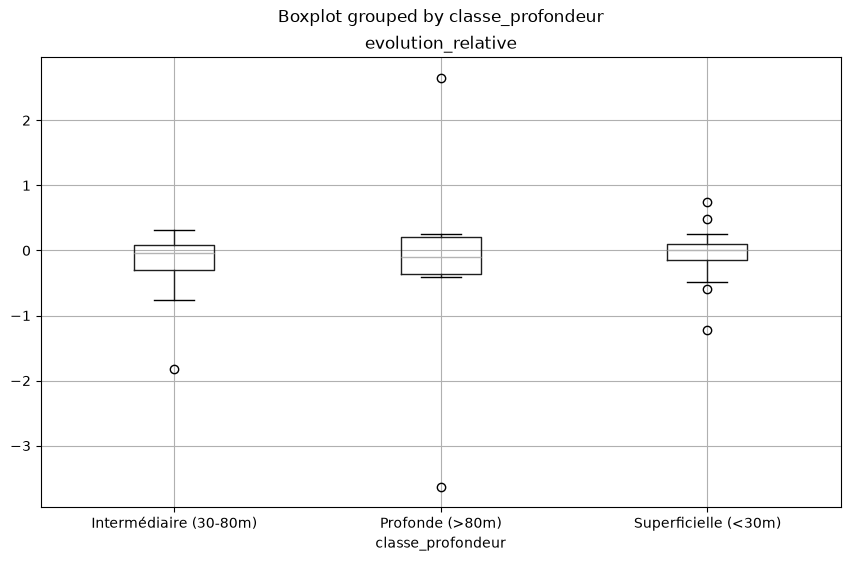

In [66]:
st.boxplot(column="evolution_relative", by="classe_profondeur", figsize=(10, 6))

### BNPE

In [67]:
prelevements = pd.read_csv("../../data/prelevements_59.csv", encoding="utf-8")
print(prelevements.groupby("annee").size())
print(prelevements.groupby("annee")["volume"].sum() / 1e6)

annee
2015    614
2016    507
2017    501
2018    512
2019    535
2020    532
2021    514
2022    551
2023    545
dtype: int64
annee
2015    474.056040
2016    453.961344
2017    431.374756
2018    385.594943
2019    368.349777
2020    458.345727
2021    446.864471
2022    404.336073
2023    391.791396
Name: volume, dtype: float64


In [68]:
url_ouvrages = "https://hubeau.eaufrance.fr/api/v1/prelevements/referentiel/ouvrages"
chemin_ouvrages = "../../data/ouvrages_59.csv"

if not os.path.exists(chemin_ouvrages):
    ouvrages = []
    url = url_ouvrages
    params_api = {"code_departement": departement_cible, "size": 5000, "format": "json"}
    while url is not None:
        reponse = rq.get(url, params=params_api, timeout=45)
        data = reponse.json()
        ouvrages.extend(data["data"])
        url = data.get("next")
        params_api = None
        time.sleep(0.5)
    ouvrages = pd.DataFrame(ouvrages)
    ouvrages.to_csv(chemin_ouvrages, index=False, encoding="utf-8")
else:
    ouvrages = pd.read_csv(chemin_ouvrages, encoding="utf-8")

print(ouvrages["libelle_type_milieu"].value_counts())

libelle_type_milieu
Souterrain             690
Surface continental     86
Name: count, dtype: int64


In [69]:
prelevements = prelevements.merge(ouvrages[["code_ouvrage", "libelle_type_milieu"]], on="code_ouvrage", how="left")
sout = prelevements[prelevements["libelle_type_milieu"].str.contains("souterrain", case=False, na=False)]
sout = gpd.GeoDataFrame(sout.drop(columns="geometry"), geometry=gpd.points_from_xy(sout["longitude"], sout["latitude"]), crs="EPSG:4326").to_crs(epsg=2154)
print(len(prelevements), "prélèvements, dont", len(sout), "souterrains")

4811 prélèvements, dont 4309 souterrains


In [70]:
part = sout.groupby("libelle_usage")["volume"].sum()
print((part / 1e6).round(1).sort_values(ascending=False))
print((100 * part / part.sum()).round(1).sort_values(ascending=False))

libelle_usage
EAU POTABLE                                                           1069.8
INDUSTRIE et ACTIVITES ECONOMIQUES (hors irrigation, hors énergie)     244.7
IRRIGATION                                                              30.5
Name: volume, dtype: float64
libelle_usage
EAU POTABLE                                                           79.5
INDUSTRIE et ACTIVITES ECONOMIQUES (hors irrigation, hors énergie)    18.2
IRRIGATION                                                             2.3
Name: volume, dtype: float64


code_usage    AEP   IND  IRR
annee                       
2015        121.9  28.4  1.8
2016        122.1  27.7  1.7
2017        123.1  24.9  2.5
2018        127.5  26.1  2.7
2019        119.6  26.6  3.8
2020        116.9  27.9  5.4
2021        113.5  28.9  1.8
2022        115.4  27.9  6.8
2023        109.7  26.4  4.0


<Axes: xlabel='annee', ylabel='Volume prélevé (millions de m³)'>

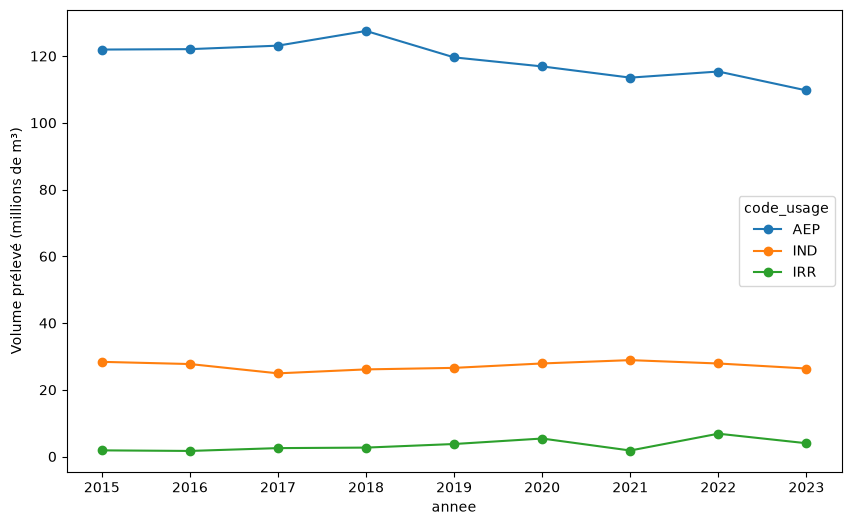

In [71]:
par_an = sout.pivot_table(values="volume", index="annee", columns="code_usage", aggfunc="sum") / 1e6
print(par_an.round(1))
par_an.plot(figsize=(10, 6), marker="o", ylabel="Volume prélevé (millions de m³)")

In [72]:
cibles = st[st["nom_commune"].isin(["Bondues", "Nieppe", "Lille"])]
for _, station in cibles.iterrows():
    proches = sout[sout.distance(station.geometry) <= 5000]
    print(station["nom_commune"])
    print((proches.groupby("code_usage")["volume"].sum() / proches["annee"].nunique() / 1e6).round(2))

Lille
code_usage
AEP    5.59
IND    1.45
IRR    0.00
Name: volume, dtype: float64
Bondues
code_usage
AEP    3.75
IND    2.08
Name: volume, dtype: float64
Lille
code_usage
AEP    1.87
IND    1.45
IRR    0.00
Name: volume, dtype: float64
Nieppe
code_usage
IRR    0.01
Name: volume, dtype: float64
Lille
code_usage
IND    4.47
IRR    0.00
Name: volume, dtype: float64
Lille
code_usage
IND    3.62
IRR    0.00
Name: volume, dtype: float64
Lille
code_usage
AEP    5.59
IND    1.41
IRR    0.00
Name: volume, dtype: float64


In [77]:
cibles = st[st["nom_commune"].isin(["Bondues", "Nieppe", "Lille"])]
for _, station in cibles.iterrows():
    proches = sout[sout.distance(station.geometry) <= 5000]
    print(station["nom_commune"], station["code_bss"], round(station["evolution_m"], 2))
    print((proches.groupby("code_usage")["volume"].sum() / proches["annee"].nunique() / 1e6).round(2))

Lille 00146B0007/F1 0.23
code_usage
AEP    5.59
IND    1.45
IRR    0.00
Name: volume, dtype: float64
Bondues 00143C0079/F1 -3.57
code_usage
AEP    3.75
IND    2.08
Name: volume, dtype: float64
Lille 00147D0218/P1 0.81
code_usage
AEP    1.87
IND    1.45
IRR    0.00
Name: volume, dtype: float64
Nieppe 00134X0127/PZ1 -1.76
code_usage
IRR    0.01
Name: volume, dtype: float64
Lille 00146B0737/PZR2 0.16
code_usage
IND    4.47
IRR    0.00
Name: volume, dtype: float64
Lille 00147X3381/PZ6 0.16
code_usage
IND    3.62
IRR    0.00
Name: volume, dtype: float64
Lille 00146X2045/PZF 0.27
code_usage
AEP    5.59
IND    1.41
IRR    0.00
Name: volume, dtype: float64


In [78]:
moy = sout.groupby(["code_ouvrage", "code_usage"]).agg(volume=("volume", "mean"), geometry=("geometry", "first")).reset_index()
moy = gpd.GeoDataFrame(moy, geometry="geometry", crs=sout.crs)

st["vol_total_5km"] = st.geometry.apply(lambda g: moy.loc[moy.distance(g) <= 5000, "volume"].sum() / 1e6)
st["vol_ind_5km"] = st.geometry.apply(lambda g: moy.loc[(moy.distance(g) <= 5000) & (moy["code_usage"] == "IND"), "volume"].sum() / 1e6)

print("Spearman volume total :", round(st["evolution_relative"].corr(st["vol_total_5km"], method="spearman"), 2))
print("Spearman volume industriel :", round(st["evolution_relative"].corr(st["vol_ind_5km"], method="spearman"), 2))

Spearman volume total : 0.16
Spearman volume industriel : 0.27


## 1. Corrélation entre installations industrielles et chute du niveau des nappes.

On cherche l'effet de l'industrie lourde, manufacturière et énergétique sur les nappes phréatiques.

In [41]:
code_naf_num = pd.to_numeric(installations_indust["code_naf"], errors="coerce")

# Filtre sur l'industrie manufacturière (10-33) et l'énergie (35)
filtre_vraie_industrie = (
    ((code_naf_num >= 10) & (code_naf_num <= 33))
    | (code_naf_num == 35)
)

installations_indust = installations_indust.loc[filtre_vraie_industrie].copy()
print("Usines manufacturières et énergétiques conservées :", len(installations_indust))


Usines manufacturières et énergétiques conservées : 428


In [42]:
# Sous-ensemble des installations lourdes
installations_lourdes = installations_indust.loc[
    (installations_indust["ied"] == 1)  #Les installations IED sont ciblées par des directives d'émissions car ce sont de gros complexes industriels
    | (installations_indust["lib_seveso"] != "Non Seveso")  #Rajoute les sites qui manipulent des substances dangereuses (Seveso).
]

nb_usines_indus_5km = []
nb_usines_lourdes_5km = []

# On compte les usines dans un rayon de 5 km pour chaque station
for geometrie_station in stations["geometry"]:
    distances_indust = installations_indust["geometry"].distance(geometrie_station)
    distances_indust_lourdes = installations_lourdes["geometry"].distance(geometrie_station)
    
    nb_usines_indus_5km.append((distances_indust <= 5000).sum())
    nb_usines_lourdes_5km.append((distances_indust_lourdes <= 5000).sum())

stations["nb_usines_indus_5km"] = nb_usines_indus_5km
stations["nb_usines_lourdes_5km"] = nb_usines_lourdes_5km

On s'intéresse maintenant à la tendance du niveau des nappes (disons sur un an).  
On pourra ainsi détecter les nappes qui s'épuisent et corréler cela avec l'activité industrielle.  
Evaluation de la tendance des nappes :

In [43]:
#tendance pluriannuelle
tendances = []

def coefficient_de_regression_lineaire(Y, X):
    Y_moy =  np.mean(Y)
    X_moy = np.mean(X)
    return np.sum((X - X_moy) * (Y - Y_moy)) / np.sum((X - X_moy)**2)

for code_station, donnees_station in chroniques.groupby("code_bss"):

    donnees_triees = donnees_station.sort_values("date_mesure")
    nb_mesures = len(donnees_triees)
    duree_etude_annees = (donnees_triees["date_mesure"].max() - donnees_triees["date_mesure"].min()).days / 365

    if duree_etude_annees >= 5 and nb_mesures >= 48: #Sinon les résultats ne sont pas fiables pour faire une régression (on dira que ça monte ou que ça chute juste parce qu'on n'a que deux points par exemple).
        temps_annees = (donnees_triees["date_mesure"] - donnees_triees["date_mesure"].min()).dt.days / 365
        pente_m_par_an = coefficient_de_regression_lineaire(donnees_triees["niveau_eau_isole"], temps_annees)
    else:
        pente_m_par_an = np.nan #Sinon on prend pas en compte les chroniques car les résultats ne seront pas significatifs

    tendances.append({
        "code_bss": code_station,
        "nb_mois_mesures": nb_mesures,
        "duree_suivi_annees": duree_etude_annees,
        "pente_m_par_an": pente_m_par_an
    })

tendances = pd.DataFrame(tendances)

stations = stations.merge(tendances, on="code_bss", how="left")

nb_fiables = stations["pente_m_par_an"].notna().sum()
print("Stations avec une tendance fiable : ", nb_fiables, " / ", len(stations))

Stations avec une tendance fiable :  55  /  67


Maintenant que nous avons créé une colonne qui indique pour chaque station la tendance annuelle (sur les données entre 2015 et 2026), on peut la croiser avec la quantité d'installations industrielles à côté.

In [44]:
stations_fiables = stations.loc[stations["pente_m_par_an"].notna()].copy()

#Corrélation linéaire entre la tendance (m/an) et le nombre d'usines à 5 km
corr_toutes = stations_fiables["pente_m_par_an"].corr(stations_fiables["nb_usines_indus_5km"])
corr_lourdes = stations_fiables["pente_m_par_an"].corr(stations_fiables["nb_usines_lourdes_5km"])

print("Corrélation tendance / nombre d'usines (dans les 5 km) :", round(corr_toutes, 3))
print("Corrélation tendance / nombre d'usines lourdes (dans les 5 km) :", round(corr_lourdes, 3))

#Découpage en deux groupes équilibrés (la médiane est à 4 usines à 5 km)
stations_fiables["niveau_pression"] = "Faible (<= 4 usines)"
stations_fiables.loc[stations_fiables["nb_usines_indus_5km"] > 4, "niveau_pression"] = "Forte (> 4 usines)"

print("")
print("Tendance (en m/an) selon la pression industrielle")
print(stations_fiables.groupby("niveau_pression")["pente_m_par_an"].agg(["count", "mean", "median"]).round(4))

print("")
print("Tendance (en m/an) selon la pression industrielle et la profondeur de nappe")
print(stations_fiables.groupby(["classe_profondeur", "niveau_pression"])["pente_m_par_an"].agg(["count", "mean", "median"]).round(4))

Corrélation tendance / nombre d'usines (dans les 5 km) : -0.136
Corrélation tendance / nombre d'usines lourdes (dans les 5 km) : -0.057

Tendance (en m/an) selon la pression industrielle
                      count    mean  median
niveau_pression                            
Faible (<= 4 usines)     29 -0.0016 -0.0111
Forte (> 4 usines)       26 -0.0585 -0.0052

Tendance (en m/an) selon la pression industrielle et la profondeur de nappe
                                             count    mean  median
classe_profondeur      niveau_pression                            
Intermédiaire (30-80m) Faible (<= 4 usines)      6 -0.0131 -0.0067
                       Forte (> 4 usines)        7 -0.0309  0.0043
Profonde (>80m)        Faible (<= 4 usines)      4  0.0835 -0.0164
                       Forte (> 4 usines)        5 -0.2677 -0.1685
Superficielle (<30m)   Faible (<= 4 usines)     19 -0.0158 -0.0111
                       Forte (> 4 usines)       14  0.0024 -0.0019


On observe que la présence d'installations industrielles a peu d'effet sur le niveau des nappes en général. Une usine de plus contribue à faire baisser le niveau de la nappe de 0.136m en moyenne.  

Les zones a forte pression industrielle (plus de 4 usines) sont même a des endroits avec un niveau des nappes plus haut (corrélation de -0.0052m en médiane) que les zones a faibe pression industrielle (-0.0111m en médiane).  

Ce qu'on remarque c'est en revanche que la corrélation est plus forte sur les couches profondes, contrairement à ce que l'on pensait. Les nappes profondes qui subissent une forte pression industrielle à moins de 5km ont une tendance annuelle de -0.27m par installation industrielle supplémentaire en moyenne (épuisement de la nappe rapide).

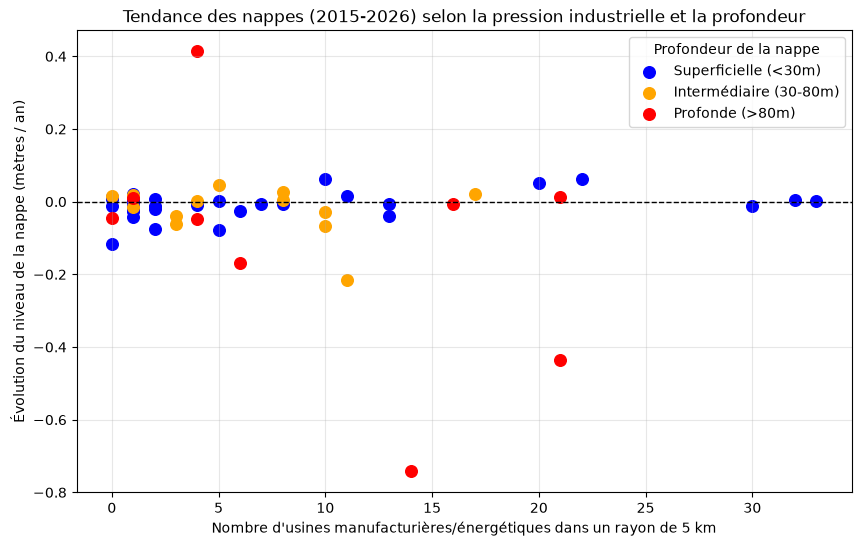

Détail des 9 stations profondes (>80m)
        code_bss             nom_commune                                                              noms_masse_eau_edl  profondeur_investigation  nb_usines_indus_5km  nb_usines_lourdes_5km  pente_m_par_an
   00143A0008/F1               Linselles ['Craie de la vallée de la Deûle', 'Calcaire carbonifère de Roubaix-Tourcoing']                    168.00                   14                      5       -0.742540
   00143C0079/F1                 Bondues                                   ['Calcaire carbonifère de Roubaix-Tourcoing']                    168.53                   21                      2       -0.434928
    BSS002PZXU/P       Quesnoy-sur-Deûle                                   ['Calcaire carbonifère de Roubaix-Tourcoing']                    149.50                    6                      2       -0.168492
   00155C0017/F1                Baisieux                                   ['Calcaire carbonifère de Roubaix-Tourcoing']             

In [54]:
plt.figure(figsize=(10, 6))

couleurs = {
    "Superficielle (<30m)": "blue",
    "Intermédiaire (30-80m)": "orange",
    "Profonde (>80m)": "red"
}

for classe, couleur in couleurs.items():
    sous_groupe = stations_fiables[stations_fiables["classe_profondeur"] == classe]
    plt.scatter(
        sous_groupe["nb_usines_indus_5km"],
        sous_groupe["pente_m_par_an"],
        color=couleur,
        label=classe,
        s=70,
    )

#Ligne horizontale à 0 : en dessous, la nappe baisse sur 2015-2026
plt.axhline(0, color="black", linestyle="--", linewidth=1)

plt.title("Tendance des nappes (2015-2026) selon la pression industrielle et la profondeur")
plt.xlabel("Nombre d'usines manufacturières/énergétiques dans un rayon de 5 km")
plt.ylabel("Évolution du niveau de la nappe (mètres / an)")
plt.legend(title="Profondeur de la nappe")
plt.grid(True, alpha=0.3)
plt.show()

# 2. Zoom sur les 9 stations profondes pour vérifier les cas extrêmes
stations_profondes = stations_fiables[stations_fiables["classe_profondeur"] == "Profonde (>80m)"]
print(f"Détail des {len(stations_profondes)} stations profondes (>80m)")
print(stations_profondes[["code_bss", "nom_commune", "noms_masse_eau_edl", "profondeur_investigation", "nb_usines_indus_5km", "nb_usines_lourdes_5km", "pente_m_par_an"]].sort_values(by="pente_m_par_an").to_string(index=False))

On voit que les nappes superficielles ont un niveau plutôt stable. Ce que l'on pensait était faux.  
Les nappes intermédiaires sont plutôt stables aussi.  
On a en revanche une forte volatilité sur les nappes profondes.  

Le tableau montre que les plus grands déclins (Linselles, Bondues, Quesnoy-sur-Deûle) sont tous dans la même nappe profonde : le Calcaire carbonifère de Roubaix-Tourcoing.  
L'activité industrielle frappe donc dûrement des nappes profondes spécifiques dont la géologie ne permet pas de se recharger rapidement.

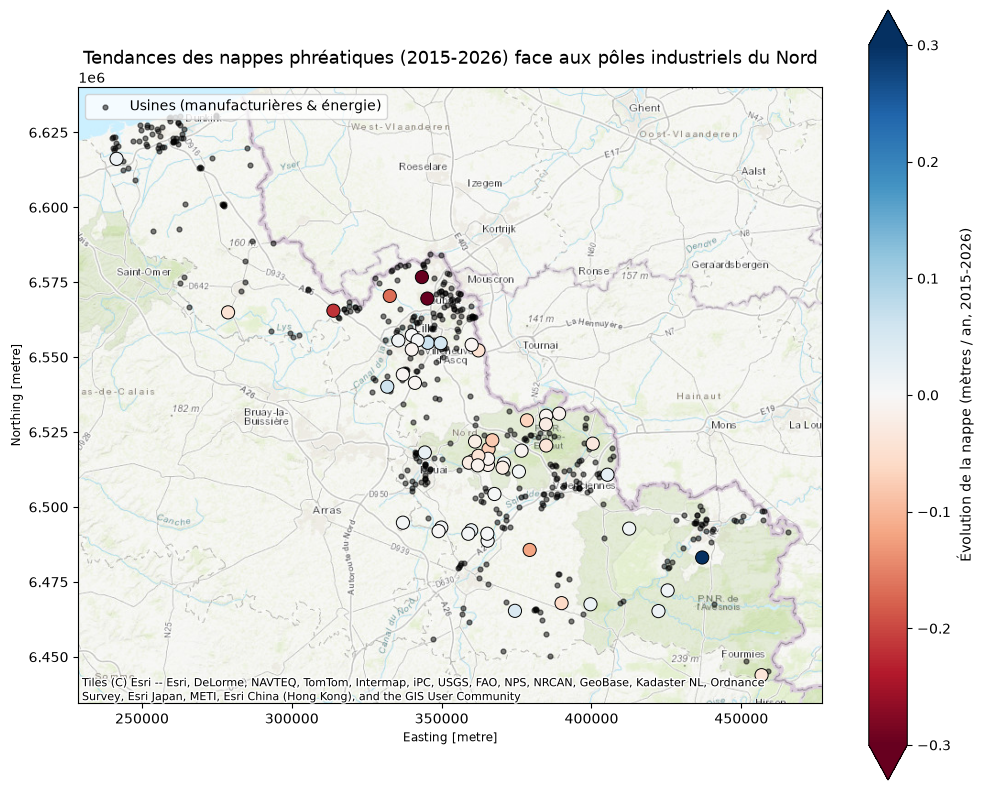

In [46]:
#On convertit les coordonnées dans un format lisable par plt
stations_carte = stations_fiables.to_crs(epsg=3857)
usines_carte = installations_indust.to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(12, 10))

#On met les points noirs (usines)
usines_carte.plot(
    ax=ax,
    color="black",
    markersize=12,
    alpha=0.5,
    label="Usines (manufacturières & énergie)",
    zorder=2
)

#On met les stations avec une couleur qui indique leur tendance.
stations_carte.plot(
    ax=ax,
    column="pente_m_par_an",
    cmap="RdBu",
    vmin=-0.3,
    vmax=0.3,
    markersize=90,
    edgecolor="black",
    linewidth=0.7,
    legend=True,
    legend_kwds={
        "label": "Évolution de la nappe (mètres / an, 2015-2026)"
    },
    zorder=3
)

#On ajoute le fond de carte
ctx.add_basemap(ax, source=ctx.providers.Esri.WorldTopoMap, zorder=1)

plt.legend(loc="upper left")
plt.title("Tendances des nappes phréatiques (2015-2026) face aux pôles industriels du Nord", fontsize=13)
plt.show()

On voit qu'il y a un endroit au Nord de Lille où les installations industrielles puisent beaucoup dans les nappes et que celles-ci ont des conditions de profondeur et de géologie qui ne leur permettent pas de se reremplir assez rapidement.  
Ailleurs, l'activité industrielle n'a plutôt pas d'impact sur la tendance du niveau des nappes.  

Ce graphique nous permet aussi de voir que l'activité industrielle n'est pas la seule à drainer les nappes phréatiques (avec le point orange sans usine autour). On va donc s'intéresser à l'impact de l'agriculture pour compléter notre étude.

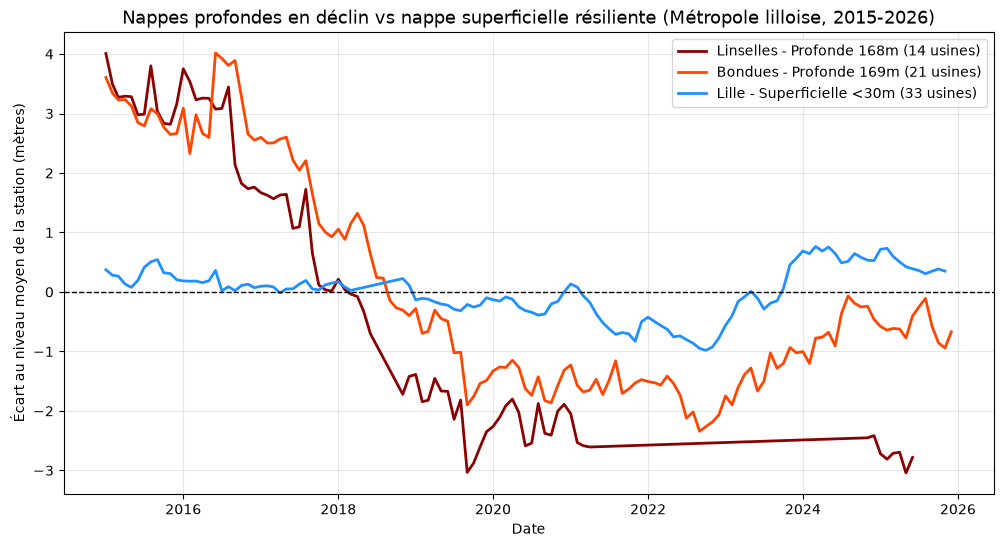

In [47]:
#On prend un exemple avec 3 stations des environs de Lille
stations_a_tracer = [
    ("00143A0008/F1", "Linselles - Profonde 168m (14 usines)", "darkred"),
    ("00143C0079/F1", "Bondues - Profonde 169m (21 usines)", "orangered"),
    ("00146B0737/PZR2", "Lille - Superficielle <30m (33 usines)", "dodgerblue")
]

plt.figure(figsize=(12, 6))

for code, etiquette, couleur in stations_a_tracer:
    serie = chroniques[chroniques["code_bss"] == code].sort_values("date_mesure")
    plt.plot(serie["date_mesure"], serie["niveau_eau_isole"], label=etiquette, color=couleur, linewidth=2)

plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.title("Nappes profondes en déclin vs nappe superficielle résiliente (Métropole lilloise, 2015-2026)", fontsize=13)
plt.xlabel("Date")
plt.ylabel("Écart au niveau moyen de la station (mètres)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Dans cet exemple, on voit que les deux nappes profondes ont une tendance largement négative (7m perdus en moins de 4 ans).  
On observe aussi notre deuxième conclusion : la nappe superficielle reste à un niveau stable malgré la présence de 33 usines dans les 5km.

Conclusion partielle :  
Les nappes phréatiques profondes du Nord de Lille de type "calcaire" sont largement impactées par l'activité industrielle (leur tendance chute).  
Les nappes phréatiques superficielles ne sont pas durablement impactées par l'activité industrielle.

## 2. Etude de la responsabilité exacte des installations industrielles dans la descente du niveau des nappes

Au-delà de la corrélation statistique entre baisse du niveau des nappes profondes du Nord de Lille avec la présence d'installations industrielles, on va vérifier les données réellees de pompage pour savoir si la baisse n'est pas due à d'autres facteurs comme l'agriculture par exemple.

In [48]:
url_bnpe = "https://hubeau.eaufrance.fr/api/v1/prelevements/chroniques"
chemin_bnpe = "../../data/prelevements_59.csv"

if not os.path.exists(chemin_bnpe):
    prelevements = []

    #comme pour le téléchargement des chroniques, les données d'extraction d'eau des usines sont trop lourdes à télécharger d'un seul coup. On va donc télécharger année après année.
    for annee in range(2015, 2026):
        url = url_bnpe
        params_api = {
            "code_departement": departement_cible,
            "annee": annee,
            "size": 2000,
            "format": "json"
        }

        while url is not None:
            try:
                reponse = rq.get(url, params=params_api, timeout=45)
            except Exception as e:
                print("Erreur... Pas grave, on recommence.")
                time.sleep(2)
                continue

            if reponse.status_code == 200 or reponse.status_code == 206:
                data = reponse.json()
                prelevements.extend(data["data"])
                url = data.get("next")
                params_api = None
                time.sleep(0.5)
            else:
                print(f"Erreur... On réessaie...")
                time.sleep(2)

        print(f"Année {annee} terminée")

    prelevements = pd.DataFrame(prelevements)
    prelevements.to_csv(chemin_bnpe, index=False, encoding="utf-8")
    print("Téléchargement réussi.")
else:
    prelevements = pd.read_csv(chemin_bnpe, encoding="utf-8")
    print("Le fichier a déjà été téléchargé.")

Année 2015 terminée
Année 2016 terminée
Année 2017 terminée
Année 2018 terminée
Année 2019 terminée
Année 2020 terminée
Année 2021 terminée
Année 2022 terminée
Année 2023 terminée
Année 2024 terminée
Année 2025 terminée
Téléchargement réussi.


Aux développeurs :  
Tu peux continuer cette partie Dany si tu veux (et faire l'agriculture si tu as du temps).

# IV. Extension à l'agriculture et à l'élevage

In [51]:
print(2)

2
